# C++ vs notebook — evaluation & comparison

Compares the two Sign-of-Life result sets produced on the same QVGA cases:

- **`results_cpp/`** — the C++ pipeline (`sign_of_life_cpp`, via `run_cpp_pipeline.py`),
- **`results_notebook/`** — the Python reference (`pipeline_experiments.ipynb`).

Both folders hold, per frame, `<frame>_raw.png` (foreground), `<frame>_morph.png`
(after morphology) and a `sign_of_life.txt` report (flag + objects). This notebook:

1. **evaluates** each result set against the CDNET groundtruth (F-measure),
2. **compares** C++ vs notebook directly — Sign-of-Life agreement, object counts
   and mask IoU,
3. **draws the bounding boxes and foreground objects** of both, side by side.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Markdown, display

from evaluate import EvaluationResult, accumulate_counts, frame_number, index_masks

CASES = ["busStation", "canoe"]
RESULTS = {"cpp": Path("results_cpp"), "notebook": Path("results_notebook")}
INPUT_ROOT = Path("data_0_1fps_qvga")   # QVGA input + groundtruth
FG_THRESHOLD = 127                      # prediction > this counts as foreground

## 1. Load the result sets

Parse each `sign_of_life.txt` into per-frame records (flag, object list) and keep
the frame order for the comparison below.

In [2]:
def parse_report(path: Path) -> dict:
    """Parse a sign_of_life.txt into {frame_name: {flag, objects:[(area,x,y,w,h)]}}."""
    records = {}
    for line in path.read_text().splitlines():
        if not line or line.startswith("#"):
            continue
        parts = line.split()
        name, flag = parts[0], int(parts[1])
        objects = []
        if len(parts) >= 4:
            for token in parts[3].split(";"):
                if not token:
                    continue
                area, box = token.split("@")
                x, y, w, h = (int(v) for v in box.split(","))
                objects.append((int(area), x, y, w, h))
        records[name] = {"flag": flag, "objects": objects}
    return records


reports = {
    source: {case: parse_report(RESULTS[source] / case / "sign_of_life.txt")
             for case in CASES}
    for source in RESULTS
}
for case in CASES:
    print(f"{case}: {len(reports['cpp'][case])} frames "
          f"(cpp) / {len(reports['notebook'][case])} frames (notebook)")

busStation: 6 frames (cpp) / 6 frames (notebook)
canoe: 5 frames (cpp) / 5 frames (notebook)


## 2. Evaluation against groundtruth

Score both the raw foreground and the post-morphology mask of each result set
against the QVGA CDNET groundtruth (`data_0_1fps_qvga/<case>/groundtruth`). Only
pixels whose groundtruth is `0` or `255` are counted; all-void frames are
skipped. The two sources should score almost identically — the C++ port
reproduces the Python pipeline.

In [3]:
def evaluate_masks(case: str, source: str, kind: str) -> dict:
    """F-measure of a result set's masks (kind = 'raw' or 'morph') vs groundtruth."""
    groundtruth = index_masks(INPUT_ROOT / case / "groundtruth")
    result_dir = RESULTS[source] / case
    tp = fp = fn = tn = frames = 0
    for name in reports[source][case]:
        number = frame_number(Path(name))
        if number not in groundtruth:
            continue
        gt = cv2.imread(str(groundtruth[number]), cv2.IMREAD_GRAYSCALE)
        pred = cv2.imread(str(result_dir / f"{Path(name).stem}_{kind}.png"),
                          cv2.IMREAD_GRAYSCALE)
        counts = accumulate_counts(gt, pred, FG_THRESHOLD)
        if sum(counts) == 0:
            continue
        tp += counts[0]; fp += counts[1]; fn += counts[2]; tn += counts[3]
        frames += 1
    result = EvaluationResult.from_counts(tp, fp, fn, tn, frames)
    return {"case": case, "source": source, "mask": kind, "eval frames": result.frames,
            "precision": result.precision, "recall": result.recall,
            "F-measure": result.f_measure, "IoU": result.iou}


rows = [evaluate_masks(case, source, kind)
        for case in CASES for kind in ("raw", "morph") for source in RESULTS]
scores = pd.DataFrame(rows)
scores.style.format(
    {"precision": "{:.3f}", "recall": "{:.3f}", "F-measure": "{:.3f}", "IoU": "{:.3f}"}
).hide(axis="index").background_gradient(subset=["F-measure"], cmap="RdYlGn", vmin=0, vmax=1)

case,source,mask,eval frames,precision,recall,F-measure,IoU
busStation,cpp,raw,4,0.878,0.617,0.725,0.569
busStation,notebook,raw,4,0.873,0.622,0.726,0.570
busStation,cpp,morph,4,0.989,0.679,0.805,0.674
busStation,notebook,morph,4,0.988,0.682,0.807,0.676
canoe,cpp,raw,1,0.608,0.859,0.712,0.553
canoe,notebook,raw,1,0.607,0.859,0.711,0.552
canoe,cpp,morph,1,0.915,0.927,0.921,0.853
canoe,notebook,morph,1,0.917,0.935,0.926,0.862


## 3. C++ vs notebook agreement

Direct per-frame comparison of the two result sets (not against groundtruth):

- **Sign of Life** — do the flags agree?
- **objects** — object counts from each report,
- **mask IoU** — pixel overlap of the two foreground masks
  (`|A∩B| / |A∪B|`; `1.0` when both are empty).

In [4]:
def mask_iou(a: np.ndarray, b: np.ndarray) -> float:
    fa, fb = a > FG_THRESHOLD, b > FG_THRESHOLD
    union = np.count_nonzero(fa | fb)
    if union == 0:
        return 1.0
    return np.count_nonzero(fa & fb) / union


def agreement_table(case: str) -> pd.DataFrame:
    rows = []
    for name in reports["cpp"][case]:
        stem = Path(name).stem
        cpp = reports["cpp"][case][name]
        nb = reports["notebook"][case][name]
        ious = {}
        for kind in ("raw", "morph"):
            a = cv2.imread(str(RESULTS["cpp"] / case / f"{stem}_{kind}.png"), 0)
            b = cv2.imread(str(RESULTS["notebook"] / case / f"{stem}_{kind}.png"), 0)
            ious[kind] = mask_iou(a, b)
        rows.append({
            "frame": name,
            "SoL cpp": bool(cpp["flag"]),
            "SoL nb": bool(nb["flag"]),
            "flag match": cpp["flag"] == nb["flag"],
            "obj cpp": len(cpp["objects"]),
            "obj nb": len(nb["objects"]),
            "raw IoU": ious["raw"],
            "morph IoU": ious["morph"],
        })
    return pd.DataFrame(rows)


for case in CASES:
    table = agreement_table(case)
    flag_ok = table["flag match"].mean() * 100
    display(Markdown(f"#### {case} — flags agree on {flag_ok:.0f}% of frames, "
                     f"mean morph IoU {table['morph IoU'].mean():.3f}"))
    display(
        table.style.hide(axis="index")
        .format({"raw IoU": "{:.3f}", "morph IoU": "{:.3f}"})
        .background_gradient(subset=["morph IoU"], cmap="RdYlGn", vmin=0, vmax=1)
    )

#### busStation — flags agree on 100% of frames, mean morph IoU 0.974

frame,SoL cpp,SoL nb,flag match,obj cpp,obj nb,raw IoU,morph IoU
in000001.jpg,False,False,True,0,0,1.000,1.000
in000241.jpg,False,False,True,0,0,0.694,1.000
in000481.jpg,True,True,True,1,1,0.932,0.957
in000721.jpg,True,True,True,1,1,0.907,0.925
in000961.jpg,True,True,True,2,2,0.951,0.962
in001201.jpg,False,False,True,0,0,0.939,1.000


#### canoe — flags agree on 100% of frames, mean morph IoU 0.943

frame,SoL cpp,SoL nb,flag match,obj cpp,obj nb,raw IoU,morph IoU
in000001.jpg,False,False,True,0,0,1.000,1.000
in000241.jpg,False,False,True,1,1,0.923,0.727
in000481.jpg,False,False,True,0,0,0.915,1.000
in000721.jpg,False,False,True,0,0,0.887,1.000
in000961.jpg,True,True,True,2,2,0.967,0.986


## 4. Bounding boxes & foreground objects

Per frame: the input image with **both** sets' object bounding boxes overlaid
(**red = C++**, **dashed lime = notebook**), next to each set's foreground-object
mask (post-morphology). Boxes come straight from the `sign_of_life.txt` reports.

In [5]:
COLUMNS = ["Input + bboxes (red=C++, lime=notebook)", "C++ objects", "Notebook objects"]


def draw_boxes(ax, objects, colour, style="-"):
    for area, x, y, w, h in objects:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=colour,
                               linewidth=1.6, linestyle=style))


def show_case(case: str) -> None:
    names = list(reports["cpp"][case])
    fig, axes = plt.subplots(len(names), 3, figsize=(12, 3.1 * len(names)))
    axes = np.atleast_2d(axes)
    for r, name in enumerate(names):
        stem = Path(name).stem
        image = cv2.imread(str(INPUT_ROOT / case / "input" / name))[:, :, ::-1]
        cpp_morph = cv2.imread(str(RESULTS["cpp"] / case / f"{stem}_morph.png"), 0)
        nb_morph = cv2.imread(str(RESULTS["notebook"] / case / f"{stem}_morph.png"), 0)
        cpp_obj = reports["cpp"][case][name]["objects"]
        nb_obj = reports["notebook"][case][name]["objects"]

        axes[r][0].imshow(image)
        draw_boxes(axes[r][0], cpp_obj, "red")
        draw_boxes(axes[r][0], nb_obj, "lime", style="--")
        axes[r][1].imshow(cpp_morph, cmap="gray", vmin=0, vmax=255)
        axes[r][2].imshow(nb_morph, cmap="gray", vmin=0, vmax=255)

        for c in range(3):
            axes[r][c].set_xticks([]); axes[r][c].set_yticks([])
            if r == 0:
                axes[r][c].set_title(COLUMNS[c], fontsize=10)
        sol = reports["cpp"][case][name]["flag"], reports["notebook"][case][name]["flag"]
        axes[r][0].set_ylabel(f"{name}\nSoL c/n={sol[0]}/{sol[1]}", fontsize=9)
    fig.suptitle(f"{case} — bounding boxes & foreground objects", fontsize=13)
    fig.tight_layout()
    plt.show()

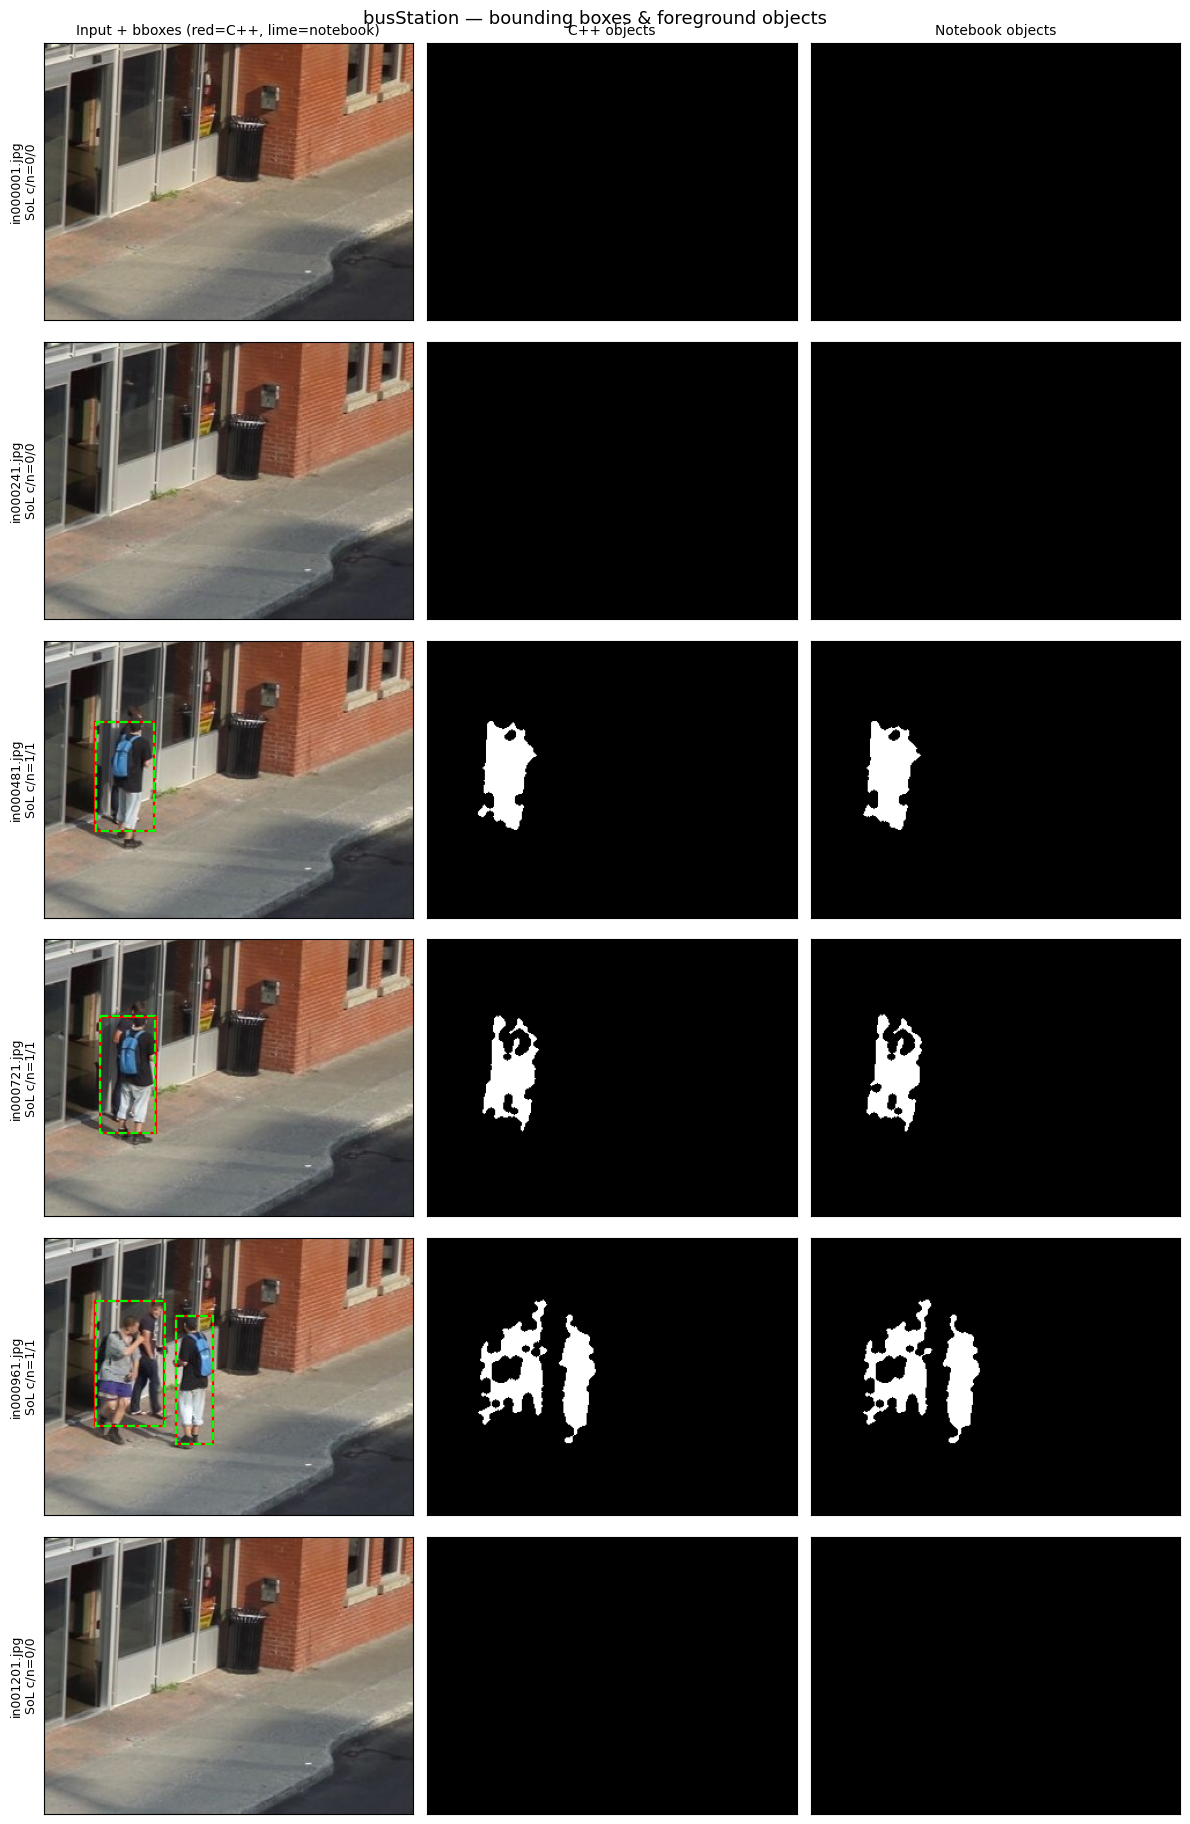

In [6]:
show_case('busStation')

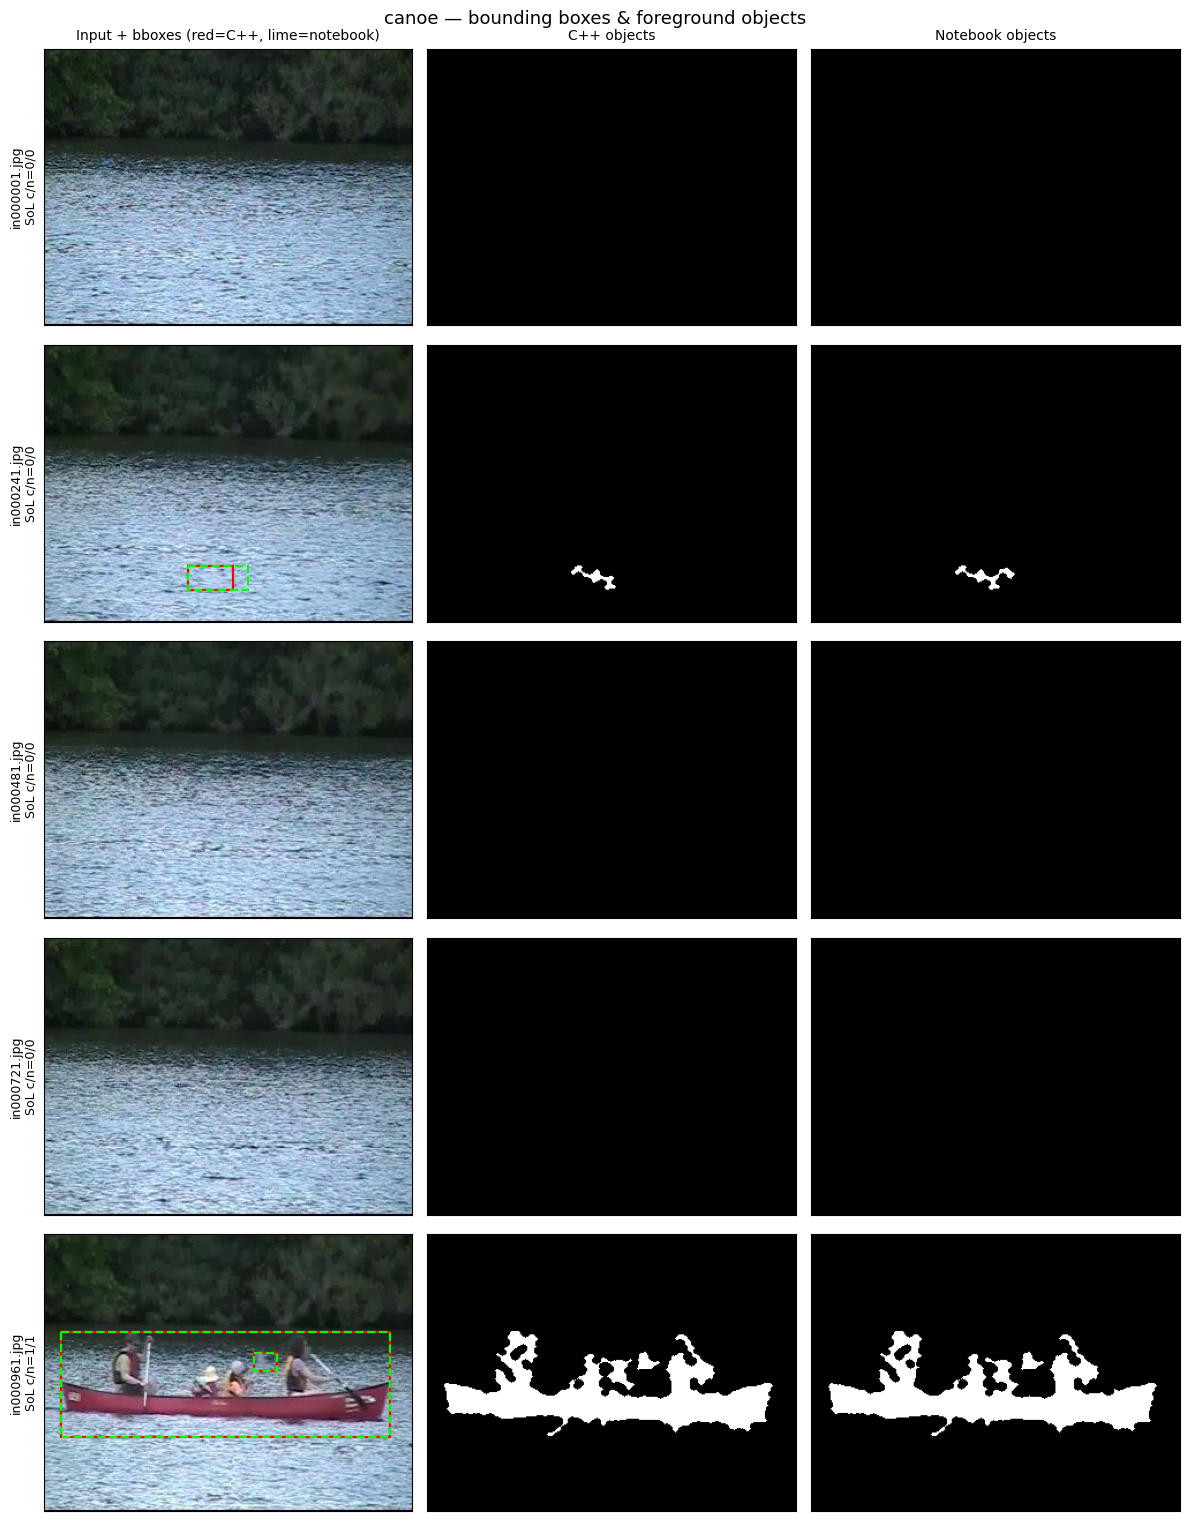

In [7]:
show_case('canoe')

### Notes

- **C++ ≈ notebook.** The two pipelines share the same configuration; differences
  come only from the float `GaussianBlur` (cv2 vs the C++ port) and gray/HSV
  rounding, so mask IoUs are high and the Sign-of-Life flags agree.
- **Thin groundtruth.** At 0.1 fps only a few frames carry `{0,255}` labels, so
  the §2 F-measures are indicative, not statistically tight.
- Boxes and objects are taken from the reports; both sets were produced at QVGA
  (320×240), so they overlay directly on the QVGA input.